<a href="https://colab.research.google.com/github/MarcinPlodzien/deep-learning-for-scientific-discovery/blob/main/notebooks/lecture-09/galaxy-classification-tree.ipynb"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open in Colab"></a>

In [ ]:
#| code-fold: true
#| code-summary: Load supporting course files when running in Colab
from pathlib import Path
from urllib.request import urlretrieve
for name in ['lecture09_data.py', 'data/galaxy10_measurements.csv']:
    target = Path(name)
    if not target.exists():
        target.parent.mkdir(parents=True, exist_ok=True)
        urlretrieve('https://raw.githubusercontent.com/MarcinPlodzien/deep-learning-for-scientific-discovery/main/notebooks/lecture-09/' + name, target)

# A readable tree for galaxy images

We classify smooth galaxies as round, intermediate or cigar-shaped. A supplied descriptor measures roundness and another measures concentration of brightness. We fit scikit-learn directly and inspect the learned questions. The companion notebook compares all three methods on these measurements and on reduced image pixels.

Keep `lecture09_data.py` and the `data` folder alongside this notebook. The helper loads or prepares the images. With no image cache it downloads the 2.7 GB Galaxy10 file. The foundations notebook uses only the supplied CSV and needs no image download. The dataset is Galaxy10 DECaLS, [Zenodo](https://doi.org/10.5281/zenodo.10845026).

In [1]:
import json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris, load_diabetes, load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor, plot_tree
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.neural_network import MLPClassifier, MLPRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.compose import TransformedTargetRegressor
from sklearn.dummy import DummyClassifier, DummyRegressor
from sklearn.metrics import balanced_accuracy_score, root_mean_squared_error, ConfusionMatrixDisplay
from threadpoolctl import threadpool_limits
threadpool_limits(limits=2)
SEED = 1975
Path("results").mkdir(exist_ok=True)
Path("figures").mkdir(exist_ok=True)

fitting / validation / test galaxies: 3407 853 746
validation galaxy 4234 {'area': np.float64(0.327), 'brightness': np.float64(344.08), 'r50': np.float64(10.637), 'q': np.float64(0.909), 'red-blue': np.float64(0.246), 'C': np.float64(1.713), 'offset': np.float64(0.186), 'failure': np.float64(0.0)}
Fitting / validation / test 3407 853 746


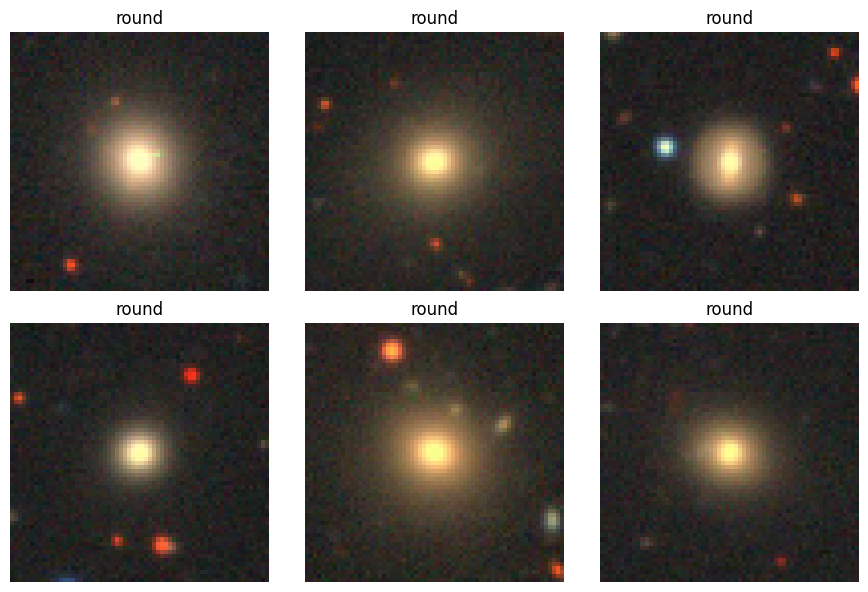

In [2]:
from lecture09_data import load_galaxies
from sklearn.impute import SimpleImputer
images, labels, descriptors, feature_names = load_galaxies()
table = pd.read_csv("data/galaxy10_measurements.csv")
smooth = table.catalogue_class.isin([2, 3, 4])
fit, val, test = [table.index[smooth & (table.split == role)].to_numpy()
                  for role in ["fitting", "validation", "test"]]
y = labels - 2
class_names = ["round", "intermediate", "cigar-shaped"]
print("Fitting / validation / test", len(fit), len(val), len(test))
fig, axes = plt.subplots(2, 3, figsize=(9, 6))
for ax, row in zip(axes.flat, fit[:6]):
    ax.imshow(images[row]); ax.set_title(class_names[y[row]]); ax.axis("off")
plt.tight_layout(); plt.show()

## Fit a short tree

Only fitting labels determine the questions. The pipeline replaces a failed measurement using fitting medians. The maximum depth is two and every leaf needs at least ten fitting objects. Read the questions before following one validation galaxy.

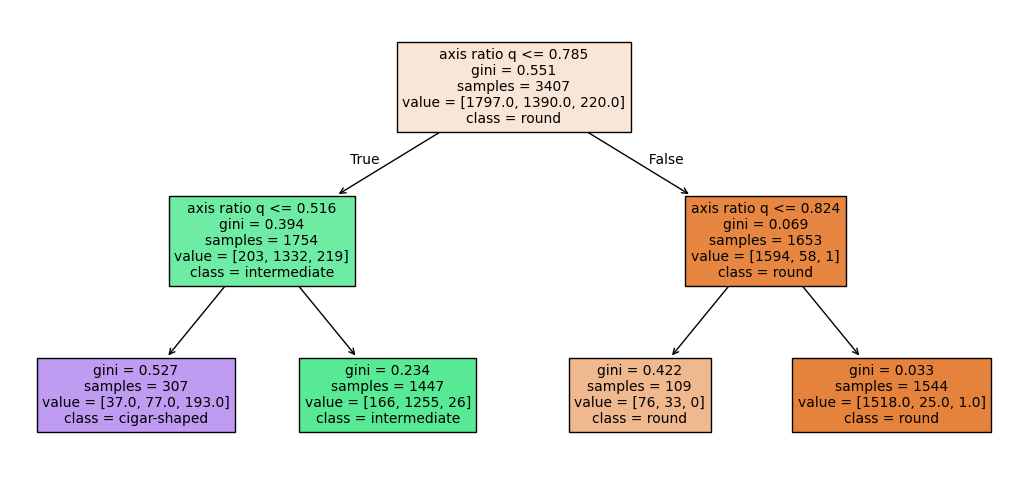

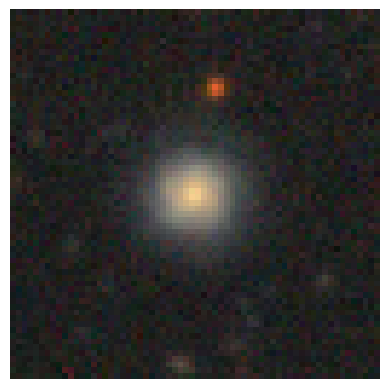

Features [0.97232556 1.69066657 0.        ]
Prediction [0]
Probabilities [[9.83160622e-01 1.61917098e-02 6.47668394e-04]]
Catalogue class round


In [3]:
shape = [3, 5, 7]
model = make_pipeline(SimpleImputer(strategy="median"),
                      DecisionTreeClassifier(max_depth=2, min_samples_leaf=10, random_state=SEED))
model.fit(descriptors[fit][:, shape], y[fit])
fig, ax = plt.subplots(figsize=(13, 6))
plot_tree(model[-1], feature_names=["axis ratio q", "concentration C", "mask failure"],
          class_names=class_names, filled=True, ax=ax, fontsize=10)
plt.show()
row = val[0]
plt.imshow(images[row]); plt.axis("off"); plt.show()
print("Features", descriptors[row, shape])
print("Prediction", model.predict(descriptors[row:row+1, shape]))
print("Probabilities", model.predict_proba(descriptors[row:row+1, shape]))
print("Catalogue class", class_names[y[row]])

## Choose depth with validation data

Compare candidate depths using all eight supplied measurements. The score is balanced accuracy. Ties go to the smaller depth. The test observations remain outside the selection.

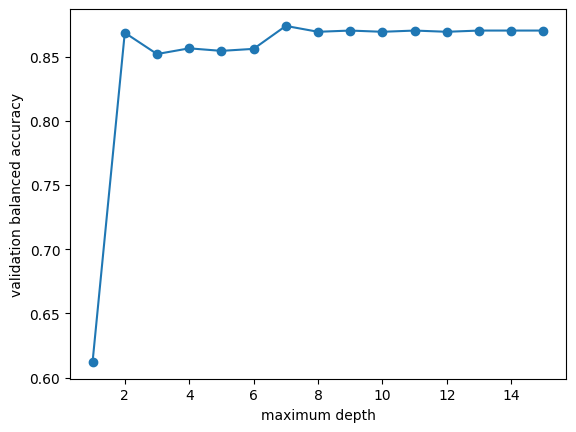

Selected depth 7
Frozen-model test BA 0.8754069351704469


In [4]:
depths = list(range(1, 16))
trees, scores = [], []
for depth in depths:
    candidate = make_pipeline(SimpleImputer(strategy="median"), DecisionTreeClassifier(
        max_depth=depth, min_samples_leaf=10, random_state=SEED)).fit(descriptors[fit], y[fit])
    trees.append(candidate)
    scores.append(balanced_accuracy_score(y[val], candidate.predict(descriptors[val])))
selected = trees[int(np.argmax(scores))]
plt.plot(depths, scores, "o-"); plt.xlabel("maximum depth"); plt.ylabel("validation balanced accuracy"); plt.show()
print("Selected depth", depths[int(np.argmax(scores))])
print("Frozen-model test BA", balanced_accuracy_score(y[test], selected.predict(descriptors[test])))

## Inspect feature reliance

The fitted tree exposes `feature_importances_`. The values summarize its use of the supplied features. A large value describes this model's reliance and does not establish a physical cause. An offset of the measured centre can indicate a mask contaminated by a neighbouring object. Inspect the image and measurement process before interpreting such a feature physically.

In [5]:
display(pd.DataFrame({"feature": feature_names, "importance": selected[-1].feature_importances_})
        .sort_values("importance", ascending=False))

,feature,importance
3,axis ratio q,0.828350
6,centre offset (px),0.123161
5,concentration C,0.013000
4,red-blue index,0.011519
1,brightness sum,0.010552
0,mask area fraction,0.007512
2,half-light radius r50 (px),0.005905
7,mask failure,0.000000


## Practice

Predict the hard class and class probabilities in a leaf containing 76 round, 33 intermediate and no cigar-shaped fitting galaxies. Explain why another leaf can predict the same hard class with different probabilities.

<details><summary>Feedback</summary>

The proportions are the counts divided by 109. The largest component is round. Different proportions can share the same largest component, so a question can change probability predictions without changing hard classes.

</details>